# Diffusion models, part 1: generating digits from noise

In this notebook we build the simplest possible diffusion model. It is trained on MNIST digits **without labels**, and after training it can turn pure random noise into new handwritten digits that never existed. We cannot yet choose *which* digit it draws: that is part 2.

The notebook is long on purpose. Most cells are explanation, and the code cells are short.

**Contents**

0. The big picture
1. Data
2. The forward process: destroying images with noise
3. What should the network learn?
4. The network: a U-Net that also knows the noise level
5. Training
6. Does the denoiser work? And why one step is not enough
7. Sampling: from pure noise to a digit
8. For the mathematically curious: what the network really learns
9. Questions for discussion

Run on a GPU (Colab: *Runtime → Change runtime type → T4 GPU*). On a CPU the training is too slow.

## 0. The big picture

### What does "generating images" mean?

Think of all possible $32\times32$ grayscale images. That is a space of $1024$ numbers, so each image is a point in $\mathbb R^{1024}$. Almost all points in that space look like random static. The images that look like handwritten digits form a tiny, thin region of this space.

The training set gives us 60 000 points from that region. We can think of them as samples from an unknown probability distribution $p(x)$, "the distribution of handwritten digits". **Generating** a new digit means drawing a new sample from $p(x)$: a point that lies in the region of digits but is not one of the training images.

The difficulty is that we have no formula for $p(x)$. We cannot write down "the probability density of handwritten digits". We only have examples.

### The diffusion idea

Destroying an image is easy: add noise to it, little by little, until nothing is left but random static. Every image, whatever it was, ends up looking the same: pure Gaussian noise.

And pure Gaussian noise is something we *can* sample from: `np.random.randn`.

So the plan is:

1. **Forward process (fixed, no learning):** take real images and add noise in many small steps, until they are pure noise.
2. **Learn to undo one small step:** train a neural network that looks at a slightly noisy image and removes a little of the noise.
3. **Generate:** start from fresh pure noise and apply the network many times, each time removing a little noise. If the network has learned well, we walk all the way back into the region of digits and end up with a new digit.

A useful analogy is a drop of ink in water. Diffusion spreads it out until the water is uniformly grey. Physically you can't run that film backwards, but if you knew exactly how to "un-diffuse" one small time step, you could repeat that step and get the drop back. The network learns that small step. (The name *diffusion model* comes from exactly this physics.)

### Why not one big step?

Why not train a network to turn noise into a digit in one go? We'll answer this properly in section 6, with a picture. In short: from pure noise there are countless digits the network "could" make, and a network trained to minimise squared error answers with their *average*, which is a blur. Small steps solve this, because each small step has a much clearer correct answer.

In [1]:
# Cell 1: Setup and imports
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import numpy as np
import keras
from keras import layers, ops
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML

print(f"Keras version: {keras.__version__}")
print(f"Keras backend: {keras.config.backend()}")

Keras version: 3.13.2
Keras backend: tensorflow


## 1. Data

We scale the pixel values from $[0, 255]$ to $[-1, 1]$. Black background becomes $-1$ and white ink becomes $+1$. The reason is that the noise we add has mean 0 and standard deviation 1, so images and noise are then on a similar scale.

We also pad the $28\times28$ images to $32\times32$. The network halves the image size three times ($32 \to 16 \to 8 \to 4$), and 32 is divisible by 8.

We load the labels too, but **this notebook never uses them**. The model learns from the images only.

In [2]:
# Cell 2: Load MNIST, scale to [-1, 1] and pad to 32x32
(x_train, y_train), _ = keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 127.5 - 1.0                            # [0, 255] -> [-1, 1]
x_train = np.pad(x_train, ((0, 0), (2, 2), (2, 2)), constant_values=-1.0)  # 28x28 -> 32x32
x_train = x_train[..., None]                                                # add channel axis
y_train = y_train.astype("int32")

print(x_train.shape, x_train.min(), x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
(60000, 32, 32, 1) -1.0 1.0


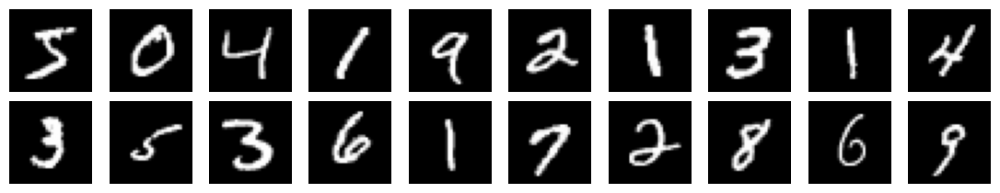

In [3]:
# Cell 3: Helpers for showing images
def to_img(x):
    # [-1, 1] -> [0, 1], drop the channel axis
    return np.clip((x[..., 0] + 1) / 2, 0, 1)

def show_grid(images, nrows, ncols, titles=None, figsize=None, suptitle=None):
    figsize = figsize or (ncols * 1.1, nrows * 1.1)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < len(images):
            ax.imshow(to_img(images[i]), cmap="gray", vmin=0, vmax=1)
            if titles is not None:
                ax.set_title(titles[i], fontsize=8)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()
show_grid(x_train[:20], 2, 10)

## 2. The forward process: destroying images with noise

### One small step

We destroy an image in $T = 1000$ small steps. At step $t$ we shrink the image a little and add a little Gaussian noise:

$$
x_t = \sqrt{1-\beta_t}\; x_{t-1} + \sqrt{\beta_t}\; \varepsilon_t, \qquad \varepsilon_t \sim \mathcal N(0, I).
$$

Here $\beta_t$ is a small number that says how much noise is added at step $t$. We let it grow linearly from $\beta_1 = 0.0001$ to $\beta_T = 0.02$: at first we add very little noise, at the end more.

**Why the square roots?** They keep the overall scale of the pixel values from growing. If $x_{t-1}$ has variance 1 and the noise is independent of it, then

$$
\operatorname{Var}(x_t) = (1-\beta_t)\cdot 1 + \beta_t \cdot 1 = 1.
$$

So the image is not just buried under more and more noise. It is gradually *replaced* by noise of the same size.

### Jumping straight to step $t$

To train the network we need noisy images at every level $t$. Running $t$ small steps every time would be slow, but there is a shortcut. Write $\alpha_t = 1 - \beta_t$. Two steps in a row give

$$
x_t = \sqrt{\alpha_t}\Big(\sqrt{\alpha_{t-1}}\,x_{t-2} + \sqrt{1-\alpha_{t-1}}\,\varepsilon_{t-1}\Big) + \sqrt{1-\alpha_t}\,\varepsilon_t .
$$

The two noise terms are independent Gaussians, and a sum of independent Gaussians is again Gaussian, with the variances adding up:

$$
\alpha_t(1-\alpha_{t-1}) + (1-\alpha_t) = 1 - \alpha_t\alpha_{t-1}.
$$

So two steps equal one step with a single noise term: $x_t = \sqrt{\alpha_t\alpha_{t-1}}\, x_{t-2} + \sqrt{1-\alpha_t\alpha_{t-1}}\,\varepsilon$. Repeating this argument all the way down to $x_0$ gives the formula we will use everywhere:

$$
\boxed{\;x_t = \sqrt{\bar\alpha_t}\; x_0 + \sqrt{1-\bar\alpha_t}\; \varepsilon, \qquad \bar\alpha_t = \alpha_1\alpha_2\cdots\alpha_t, \quad \varepsilon\sim\mathcal N(0,I).\;}
$$

Read it as a mixture: **a noisy image is a weighted mix of the clean image and one Gaussian noise image.** The weight of the image, $\sqrt{\bar\alpha_t}$, falls from 1 to almost 0. The weight of the noise, $\sqrt{1-\bar\alpha_t}$, rises from 0 to almost 1.

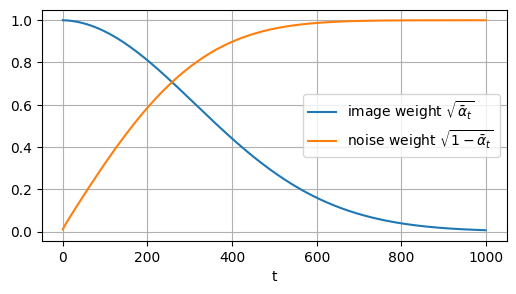

In [4]:
# Cell 4: Noise schedule
T = 1000
betas = np.linspace(1e-4, 0.02, T).astype("float32")   # noise added at each step
alphas = 1.0 - betas
alpha_bars = np.cumprod(alphas).astype("float32")      # alpha_bar_t = alpha_1 * ... * alpha_t

def add_noise(x0, t, eps):
    # Jump straight to noise level t:  x_t = sqrt(alpha_bar_t) * x0 + sqrt(1 - alpha_bar_t) * eps
    a = alpha_bars[t].reshape(-1, 1, 1, 1)
    return np.sqrt(a) * x0 + np.sqrt(1.0 - a) * eps
plt.figure(figsize=(6, 3))
plt.plot(np.sqrt(alpha_bars), label=r"image weight $\sqrt{\bar\alpha_t}$")
plt.plot(np.sqrt(1 - alpha_bars), label=r"noise weight $\sqrt{1-\bar\alpha_t}$")
plt.xlabel("t"); plt.legend(); plt.grid(); plt.show()

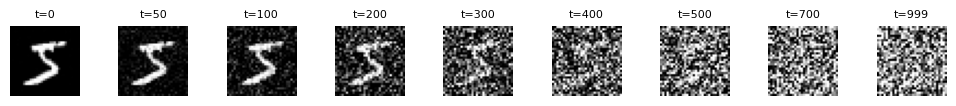

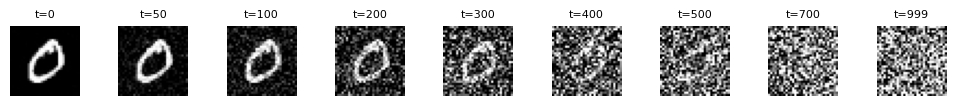

In [5]:
# Cell 5: Two digits at increasing noise levels
rng = np.random.default_rng(0)
steps_to_show = [0, 50, 100, 200, 300, 400, 500, 700, 999]
for k in [0, 1]:
    x0 = np.repeat(x_train[k:k + 1], len(steps_to_show), axis=0)
    eps = rng.standard_normal(x0.shape).astype("float32")
    xt = add_noise(x0, np.array(steps_to_show), eps)
    show_grid(xt, 1, len(steps_to_show), titles=[f"t={t}" for t in steps_to_show])

At $t = 999$ the two digits look the same: they are both just noise. The histogram below checks this. The pixel values of real digits are almost all $-1$ (background) or close to $+1$ (ink). After 1000 steps the pixel values follow the standard normal distribution, *whatever the starting image was*. This is the point of the forward process: it leads every image to the same simple distribution, which we know how to sample.

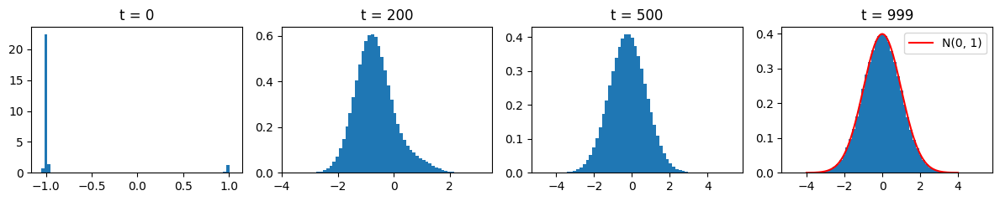

In [6]:
# Cell 6: Pixel value histograms
fig, axes = plt.subplots(1, 4, figsize=(12, 2.5))
x0 = x_train[:2000]
for ax, t in zip(axes, [0, 200, 500, 999]):
    eps = rng.standard_normal(x0.shape).astype("float32")
    xt = add_noise(x0, np.full(len(x0), t), eps)
    ax.hist(xt.ravel(), bins=60, density=True)
    ax.set_title(f"t = {t}")
grid = np.linspace(-4, 4, 200)
axes[-1].plot(grid, np.exp(-grid**2 / 2) / np.sqrt(2 * np.pi), "r", label="N(0, 1)")
axes[-1].legend()
plt.tight_layout(); plt.show()

## 3. What should the network learn?

The network will see a noisy image $x_t$ and should help us clean it. There are two natural choices for what it outputs:

* **the clean image** $x_0$, or
* **the noise** $\varepsilon$ that was mixed in.

Because $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon$ and we know $x_t$ and $t$, these two are equivalent: if we know one, we can solve for the other,

$$
x_0 = \frac{x_t - \sqrt{1-\bar\alpha_t}\;\varepsilon}{\sqrt{\bar\alpha_t}}.
$$

In practice, predicting the **noise** works better, and that is what Ho et al. did in the paper that made diffusion models popular (*Denoising Diffusion Probabilistic Models*, 2020). The target $\varepsilon$ always has the same simple scale (mean 0, variance 1) at every noise level, which makes the learning problem well-behaved.

So the network is a function $\hat\varepsilon(x_t, t)$, and we train it with the mean squared error

$$
L = \big\lVert \varepsilon - \hat\varepsilon(x_t, t) \big\rVert^2 .
$$

### Training is just regression

A training example is made like this:

1. take a real image $x_0$,
2. pick a random noise level $t$ between 0 and 999,
3. draw random noise $\varepsilon$ and compute $x_t$,
4. **input** $(x_t, t)$, **target** $\varepsilon$.

That is all. It's ordinary supervised learning with a squared error loss, like regression in a basic machine learning course. The "labels" are generated by ourselves, since we know exactly what noise we added. The same image is used again and again with different $t$ and different noise, so the training data is practically unlimited.

## 4. The network: a U-Net that also knows the noise level

The output $\hat\varepsilon$ is an image of the same size as the input, so we need an image-to-image network. We use a **U-Net**, the same type of network as in the image-repair example:

* an **encoder** that halves the image size step by step ($32\to16\to8\to4$) while increasing the number of channels. It sees larger and larger areas of the image, which lets it recognise shapes such as "this looks like the top of a 7".
* a **decoder** that doubles the size back to $32\times32$.
* **skip connections** that copy the encoder's feature maps directly to the decoder at the same resolution, so that fine details (exact stroke positions) are not lost in the bottleneck.

The building block is a **residual block**: two convolutions whose result is added to the block's input. Group normalisation and the *swish* activation are standard choices in diffusion models; nothing important depends on them.

### The new part: telling the network the noise level $t$

The same network must work at every noise level. At $t = 10$ the input is a nearly clean digit, and the network should find a faint layer of noise on it. At $t = 900$ the input is almost pure noise, and the network should guess which faint shape is hiding in it. It must know which situation it is in, so we give $t$ as a second input.

A single number is a poor input for a neural network, so we first turn $t$ into a vector of sines and cosines of different frequencies:

$$
\big(\sin(\omega_1 t), \dots, \sin(\omega_{64} t),\; \cos(\omega_1 t), \dots, \cos(\omega_{64} t)\big),
\qquad \omega_k = 10000^{-k/64}.
$$

This is exactly the *positional encoding* used in Transformers, where it encodes the position of a word. The fast frequencies separate nearby values of $t$ and the slow ones encode the overall level. A small dense network then processes this vector, and in every residual block the result is added to the feature maps, one number per channel. So every layer of the network knows how noisy the image is.

In [7]:
# Cell 7: Network building blocks
@keras.saving.register_keras_serializable()
class SinusoidalEmbedding(layers.Layer):
    # Turns the number t (shape (batch, 1)) into a vector of sines and cosines (shape (batch, dim))
    def __init__(self, dim, **kwargs):
        super().__init__(**kwargs)
        self.dim = dim

    def call(self, t):
        half = self.dim // 2
        freqs = ops.exp(-np.log(10000.0) * ops.arange(half, dtype="float32") / half)
        args = ops.cast(t, "float32") * freqs[None, :]
        return ops.concatenate([ops.sin(args), ops.cos(args)], axis=-1)

    def get_config(self):
        return {**super().get_config(), "dim": self.dim}


def res_block(x, emb, channels):
    # Residual block: two convolutions, plus the time information added to every pixel
    skip = x if x.shape[-1] == channels else layers.Conv2D(channels, 1)(x)
    h = layers.GroupNormalization(groups=8)(x)
    h = layers.Activation("swish")(h)
    h = layers.Conv2D(channels, 3, padding="same")(h)
    e = layers.Dense(channels)(emb)                 # one number per channel ...
    h = h + layers.Reshape((1, 1, channels))(e)     # ... added to every pixel of that channel
    h = layers.GroupNormalization(groups=8)(h)
    h = layers.Activation("swish")(h)
    h = layers.Conv2D(channels, 3, padding="same")(h)
    return layers.Add()([h, skip])


def unet_body(image_in, emb, widths):
    # Encoder 32 -> 16 -> 8 -> 4, bottleneck, decoder 4 -> 8 -> 16 -> 32 with skip connections
    x = layers.Conv2D(widths[0], 3, padding="same")(image_in)
    skips = []
    for w in widths:
        x = res_block(x, emb, w)
        skips.append(x)
        x = layers.Conv2D(w, 3, strides=2, padding="same")(x)      # downsample
    x = res_block(x, emb, widths[-1])
    x = res_block(x, emb, widths[-1])
    for w, s in zip(reversed(widths), reversed(skips)):
        x = layers.UpSampling2D(2)(x)                               # upsample
        x = layers.Concatenate()([x, s])                            # skip connection
        x = res_block(x, emb, w)
        x = res_block(x, emb, w)
    x = layers.GroupNormalization(groups=8)(x)
    x = layers.Activation("swish")(x)
    return layers.Conv2D(1, 3, padding="same", kernel_initializer="zeros")(x)

In [8]:
# Cell 8: The model: input (noisy image, t), output: predicted noise
def build_unet(widths=(32, 64, 128), emb_dim=128):
    image_in = keras.Input(shape=(32, 32, 1), name="noisy_image")
    t_in = keras.Input(shape=(1,), name="timestep")

    emb = SinusoidalEmbedding(emb_dim)(t_in)
    emb = layers.Dense(emb_dim, activation="swish")(emb)
    emb = layers.Dense(emb_dim, activation="swish")(emb)

    noise_out = unet_body(image_in, emb, widths)
    return keras.Model([image_in, t_in], noise_out, name="denoiser")

model = build_unet()
print(f"Parameters: {model.count_params():,}")

Parameters: 2,310,465


## 5. Training

The generator below makes the training batches exactly as described in section 3. New random $t$ and new noise are drawn for every batch, so the network never sees the same input twice.

Two practical details:

* **Learning rate.** $10^{-3}$ with the Adam optimizer works well for a model of this size.
* **Exponential moving average (EMA) of the weights.** With `use_ema=True` Keras keeps a running average of the weights during training, and after training the averaged weights replace the actual ones. The weights of a diffusion model jump around a little from batch to batch, because every batch has different random noise. The average is smoother and gives noticeably cleaner images. All serious diffusion models do this.

In [9]:
# Cell 9: Training data generator
class NoisyBatches(keras.utils.PyDataset):
    def __init__(self, x, batch_size=128, seed=0, **kwargs):
        super().__init__(**kwargs)
        self.x = x
        self.batch_size = batch_size
        self.rng = np.random.default_rng(seed)
        self.perm = self.rng.permutation(len(x))

    def __len__(self):
        return len(self.x) // self.batch_size

    def __getitem__(self, i):
        idx = self.perm[i * self.batch_size:(i + 1) * self.batch_size]
        x0 = self.x[idx]                                            # 1. clean images
        t = self.rng.integers(0, T, size=len(x0))                   # 2. random noise levels
        eps = self.rng.standard_normal(x0.shape).astype("float32")  # 3. random noise
        xt = add_noise(x0, t, eps)                                  #    noisy images
        inputs = {"noisy_image": xt, "timestep": t[:, None].astype("float32")}
        return inputs, eps                                          # 4. input, target

    def on_epoch_end(self):
        self.perm = self.rng.permutation(len(self.x))

train_data = NoisyBatches(x_train)

Epoch 1/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 75s 32ms/step - loss: 0.0659
Epoch 2/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - loss: 0.0239
Epoch 3/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - loss: 0.0219
Epoch 4/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - loss: 0.0204
Epoch 5/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - loss: 0.0196
Epoch 6/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - loss: 0.0192
Epoch 7/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - loss: 0.0192
Epoch 8/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - loss: 0.0187
Epoch 9/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - loss: 0.0185
Epoch 10/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - loss: 0.0185
Epoch 11/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - loss: 0.0184
Epoch 12/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - loss: 0.0181
Epoch 13/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - loss: 0.0179
Epoch 14/20
468/468 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - loss: 0.0179
Epoch 15/20
468/468 ━━━━━━━━━

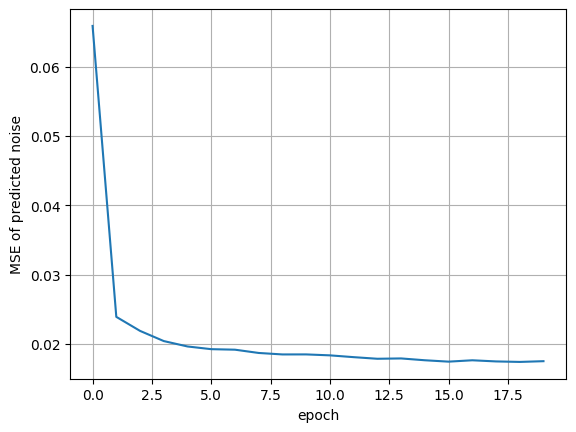

In [10]:
# Cell 10: Train
EPOCHS = 20   # check how long the first epoch takes, and reduce if needed

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3, use_ema=True, ema_momentum=0.99),
    loss="mse",
)
history = model.fit(train_data, epochs=EPOCHS)

plt.plot(history.history["loss"])
plt.xlabel("epoch"); plt.ylabel("MSE of predicted noise"); plt.grid(); plt.show()

In [11]:
# Cell 11: Save the weights (in a new session: run cells 1-8, then model.load_weights(...))
model.save_weights("diffusion_mnist_unconditional.weights.h5")

## 6. Does the denoiser work? And why one step is not enough

Let's first check the network on real digits. We noise a test digit to level $t$, let the network predict the noise, and compute its guess of the clean image with

$$
\hat x_0 = \frac{x_t - \sqrt{1-\bar\alpha_t}\;\hat\varepsilon}{\sqrt{\bar\alpha_t}}.
$$

In [12]:
# Cell 12: Helpers: predict the noise, and the guess of the clean image
def predict_eps(x, t):
    t_arr = np.full((len(x), 1), t, dtype="float32")
    return model.predict_on_batch([x, t_arr])

def predict_x0(x, t, eps):
    a = alpha_bars[t]
    return (x - np.sqrt(1 - a) * eps) / np.sqrt(a)

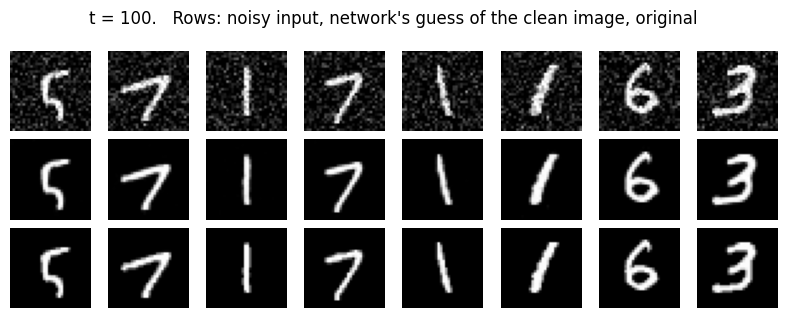

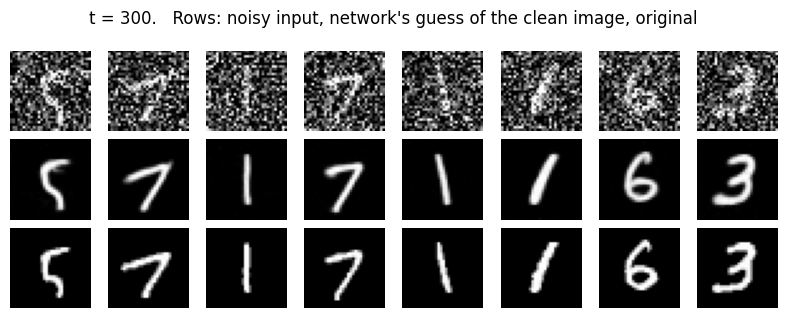

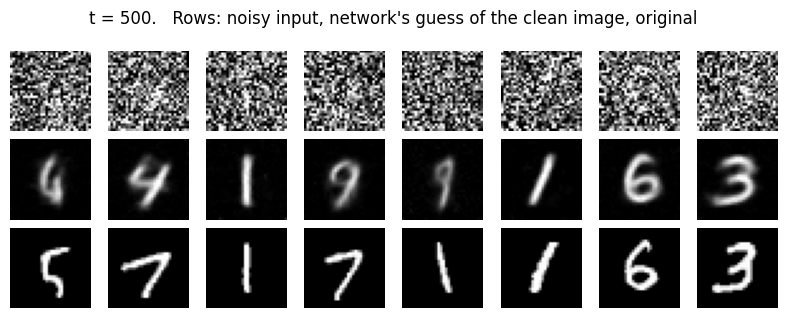

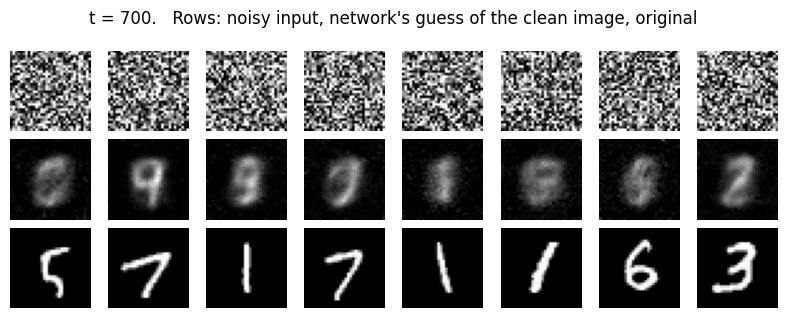

In [13]:
# Cell 13: The denoiser on real digits at different noise levels
rng = np.random.default_rng(3)
x0 = x_train[100:108]
for t in [100, 300, 500, 700]:
    eps = rng.standard_normal(x0.shape).astype("float32")
    xt = add_noise(x0, np.full(len(x0), t), eps)
    x0_hat = np.clip(predict_x0(xt, t, predict_eps(xt, t)), -1, 1)
    show_grid(np.concatenate([xt, x0_hat, x0]), 3, 8, figsize=(8, 3.2),
              suptitle=f"t = {t}.   Rows: noisy input, network's guess of the clean image, original")

What to look for:

* At low noise ($t = 100$) the guess is almost perfect.
* As the noise grows, the guess becomes **blurry**. At $t = 500$ the digit is usually still right, but the details are smoothed out.
* At $t = 700$ the network often can't tell what the digit was, and the guess becomes a soft blob that may even be a different digit.

**Why blurry?** The network is trained with squared error. The answer that minimises the expected squared error is the *average* of all clean images that could have produced this noisy input (the conditional expectation $\mathbb E[x_0 \mid x_t]$). When the noise is heavy, many different digits fit the input, and their average is a blur. The network is not failing: a blur is the honest best guess under squared error.

This is exactly why we cannot generate in one step. Below we give the network pure noise and ask for the clean image directly. (We tell it the noise level is $t = 600$. There the image weight is only $0.16$, so pure noise is a realistic input. At $t = 999$ the weight is $0.006$, and dividing by it in the formula above would blow up the tiniest errors.)

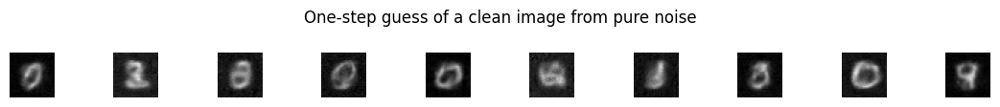

In [14]:
# Cell 14: One-step guess from pure noise
rng = np.random.default_rng(1)
x_noise = rng.standard_normal((10, 32, 32, 1)).astype("float32")
t = 600
x0_one_step = np.clip(predict_x0(x_noise, t, predict_eps(x_noise, t)), -1, 1)
show_grid(x0_one_step, 1, 10, suptitle="One-step guess of a clean image from pure noise")

We get blurry shapes: an "average digit", not a digit. To get a sharp digit, the process has to **commit** to one particular digit among all possibilities. Small steps with a little randomness do exactly that, as the next section shows.

## 7. Sampling: from pure noise to a digit

### The reverse step

Generation runs the forward process backwards. Start from pure noise $x_{T} \sim \mathcal N(0, I)$ and for $t = T-1, \dots, 1, 0$:

1. Ask the network for $\hat\varepsilon$, and compute the current guess of the clean image $\hat x_0$ (clipped to the valid pixel range $[-1, 1]$).
2. Take a small step towards that guess:

$$
x_{t-1} \;=\; \underbrace{\frac{\sqrt{\bar\alpha_{t-1}}\,\beta_t}{1-\bar\alpha_t}}_{\text{small}}\;\hat x_0
\;+\; \underbrace{\frac{\sqrt{\alpha_t}\,(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}}_{\approx 1}\; x_t
\;+\; \sigma_t\, z,
\qquad z\sim\mathcal N(0,I),\quad \sigma_t^2 = \frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\,\beta_t .
$$

In words: the new image is **mostly the current image, moved a little towards the network's guess, plus a little fresh noise**. (At the last step, $t = 0$, no noise is added.)

### Where does this formula come from?

It is not invented: it is a calculation with Gaussians. Suppose we knew the clean image $x_0$. Then, given $x_t$, the previous image $x_{t-1}$ has an exact distribution that can be computed with Bayes' formula, because all the distributions involved are Gaussian:

$$
q(x_{t-1} \mid x_t, x_0) \;\propto\; q(x_t \mid x_{t-1})\; q(x_{t-1} \mid x_0).
$$

Both factors on the right are Gaussian densities in $x_{t-1}$ (from the one-step formula and the jump formula of section 2). A product of Gaussian densities is a Gaussian density, and completing the square gives its mean and variance: exactly the two weights and the $\sigma_t^2$ above. In generation we don't know $x_0$, so we plug in the network's guess $\hat x_0$. This is Algorithm 2 in Ho et al. (2020). They write it with $\hat\varepsilon$ instead of $\hat x_0$, but the two forms are algebraically the same.

### Why add fresh noise at every step?

This is the most surprising part, and the most important one.

* The reverse step is **random** because the true reverse process is random: many different slightly-less-noisy images are consistent with the current one. Adding $\sigma_t z$ means we *sample* one of them instead of always taking their average.
* Early on, when $\hat x_0$ is a blurry average, the noise lets the process drift towards one particular digit. Once the process has started to become, say, a 3, the network's next guesses are sharper 3s, and the process commits more and more. This is how the blur of section 6 turns into a sharp digit.
* Small errors of the network are also washed out by the fresh noise instead of piling up.

The starting noise and the noise added along the way decide which digit comes out. That is why the result is a **random** digit, and why a different random seed gives a different one.

In [15]:
# Cell 15: The sampler
def sample(n, seed=None, record_every=None):
    rng = np.random.default_rng(seed)
    x = rng.standard_normal((n, 32, 32, 1)).astype("float32")      # start from pure noise
    frames = []                                                     # snapshots for pictures
    for t in reversed(range(T)):
        eps = predict_eps(x, t)
        x0 = np.clip(predict_x0(x, t, eps), -1, 1)                  # current guess of the clean image
        a_bar, a_bar_prev = alpha_bars[t], (alpha_bars[t - 1] if t > 0 else 1.0)
        coef_x0 = np.sqrt(a_bar_prev) * betas[t] / (1 - a_bar)
        coef_xt = np.sqrt(alphas[t]) * (1 - a_bar_prev) / (1 - a_bar)
        x = coef_x0 * x0 + coef_xt * x                              # small step towards the guess
        if t > 0:
            sigma = np.sqrt((1 - a_bar_prev) / (1 - a_bar) * betas[t])
            x = x + sigma * rng.standard_normal(x.shape).astype("float32")   # fresh noise
        if record_every and (t % record_every == 0 or t == T - 1):
            frames.append((t, x.copy(), x0.copy()))
    return (x, frames) if record_every else x

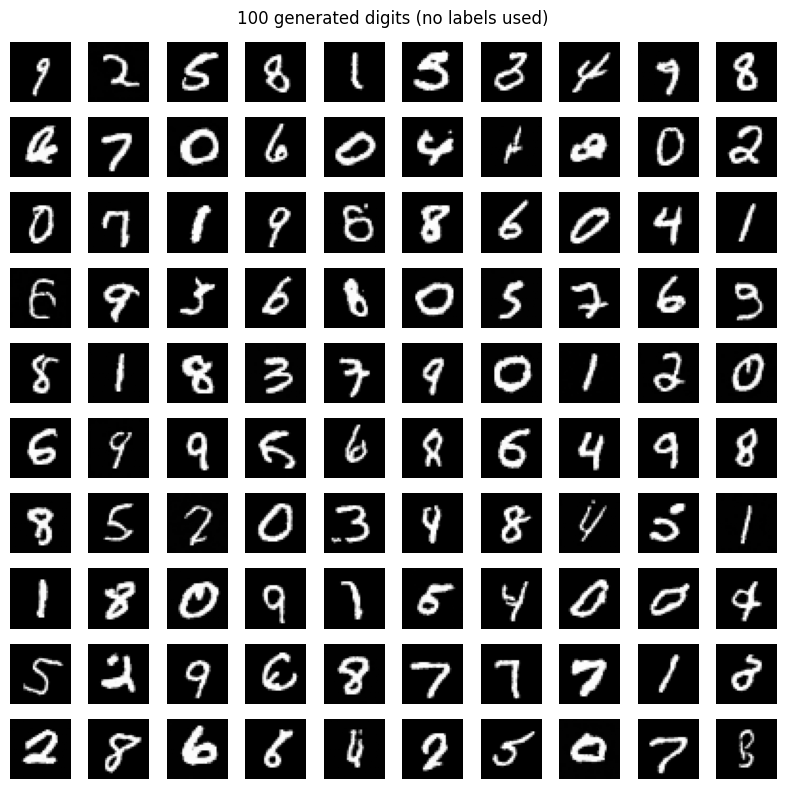

In [16]:
# Cell 16: 100 new digits
samples = sample(100, seed=42)
show_grid(samples, 10, 10, figsize=(8, 8), suptitle="100 generated digits (no labels used)")

The model draws all kinds of digits, in random order. It has learned the *whole* distribution of handwritten digits, but we have no way to ask for a particular one. That is the topic of part 2.

Next, let's watch one digit being born. The top row is the image $x_t$ during sampling. The bottom row is the network's guess $\hat x_0$ at the same moment. Notice how the guess starts as a blurry average and becomes sharper, and how it can still change its mind in the middle (a blob that could be a 3 or a 5 becomes one of them).

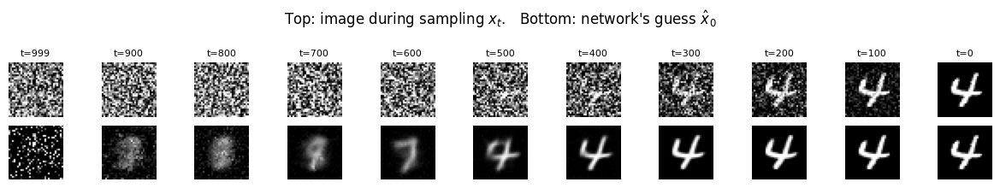

In [17]:
# Cell 17: One digit, step by step
_, frames = sample(1, seed=7, record_every=1)
show_t = [999, 900, 800, 700, 600, 500, 400, 300, 200, 100, 0]
by_t = {t: (xt, x0) for t, xt, x0 in frames}
show_grid([by_t[t][0][0] for t in show_t] + [by_t[t][1][0] for t in show_t], 2, len(show_t),
          titles=[f"t={t}" for t in show_t] + [""] * len(show_t),
          suptitle=r"Top: image during sampling $x_t$.   Bottom: network's guess $\hat x_0$")

In [18]:
# Cell 18: Animation of 16 digits being generated
def tile(batch, ncols=8):
    imgs = to_img(batch)
    rows = [np.concatenate(list(imgs[i:i + ncols]), axis=1) for i in range(0, len(imgs), ncols)]
    return np.concatenate(rows, axis=0)

def animate(frames, ncols=8):
    fig, ax = plt.subplots(figsize=(ncols, 2.2 * len(frames[0][1]) / ncols / 2 + 0.4))
    ax.axis("off")
    im = ax.imshow(tile(frames[0][1], ncols), cmap="gray", vmin=0, vmax=1)
    title = ax.set_title("")
    def update(i):
        t, xt, _ = frames[i]
        im.set_data(tile(xt, ncols))
        title.set_text(f"t = {t}")
        return im, title
    anim = animation.FuncAnimation(fig, update, frames=len(frames), interval=80)
    plt.close(fig)
    return HTML(anim.to_jshtml())

_, frames = sample(16, seed=3, record_every=20)
animate(frames)

### The role of the random seed

The same seed gives the same digit, and a different seed gives a different digit. Below, the first two rows use seed 0 twice: they are identical. The last row uses seed 1.

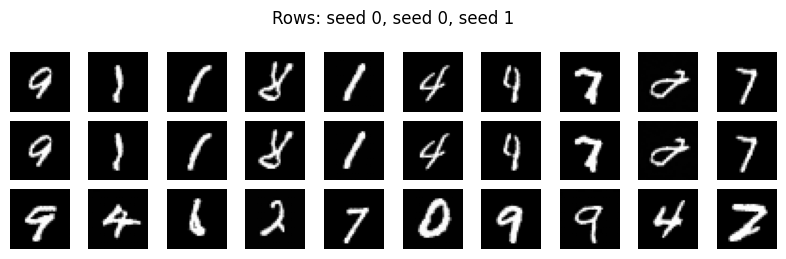

In [19]:
# Cell 19: Same seed = same digits
show_grid(np.concatenate([sample(10, seed=0), sample(10, seed=0), sample(10, seed=1)]), 3, 10,
          figsize=(8, 2.6), suptitle="Rows: seed 0, seed 0, seed 1")

## 8. For the mathematically curious: what the network really learns

This section is optional, but it connects diffusion models to two familiar ideas: **the gradient** and **gradient ascent**.

### The score

Let $p_t(x)$ be the probability density of noisy images at level $t$ (blurred digits, slightly noisier at each $t$). Its **score** is the gradient of the log-density,

$$
s_t(x) = \nabla_x \log p_t(x).
$$

It is a vector field in $\mathbb R^{1024}$: at each point it points in the direction where the density grows fastest, that is, *towards more probable images*. Following it is gradient ascent on $\log p_t$.

### The noise predictor is the score

A classical result (Tweedie's formula) says that for Gaussian noise,

$$
\mathbb E[x_0 \mid x_t] = \frac{x_t + (1-\bar\alpha_t)\,\nabla \log p_t(x_t)}{\sqrt{\bar\alpha_t}} .
$$

Compare this with our guess $\hat x_0 = \big(x_t - \sqrt{1-\bar\alpha_t}\,\hat\varepsilon\big)/\sqrt{\bar\alpha_t}$. We saw in section 6 that the best squared-error guess $\hat x_0$ *is* $\mathbb E[x_0\mid x_t]$. Setting the two equal gives

$$
\hat\varepsilon(x_t, t) \;\approx\; -\sqrt{1-\bar\alpha_t}\;\nabla \log p_t(x_t).
$$

**The network that predicts the noise has learned the gradient of the log-density of the data, at every noise level**, even though we never wrote down any density. "Subtract the predicted noise" means "take a step uphill in probability".

### Sampling as noisy gradient ascent

So the sampler of section 7 is, in essence: *take a small gradient step towards more probable images, add a little noise, repeat*, while the noise level slowly decreases. This is closely related to **Langevin dynamics** from physics, a classical method for sampling from a distribution when you know its score.

Why not do plain gradient ascent without noise? Gradient ascent climbs to the nearest peak of the density and stays there, so you would always get the most "typical" blurred image. The noise keeps the process exploring, so that the final images are spread out over the whole distribution like real samples. And why start at high noise? For heavily noised data the density $p_t$ is smooth and simple, almost a single Gaussian bump, so its gradient is easy to learn and follow. As $t$ decreases the landscape slowly gains the fine structure of real digits, and the process is guided into it step by step.

This view comes from Song & Ermon (2019) and Song et al. (2021, *Score-based generative modeling through stochastic differential equations*), who showed that it describes the same models as Ho et al.

## 9. Questions for discussion

1. In section 6 the one-step guess was blurry. Would it still be blurry if MNIST contained only one image? What about if it contained only images of the digit 1?
2. Why does the network need to know $t$? What do you think would happen if we removed the time input?
3. Try sampling without the fresh noise: in cell 15, comment out the line `x = x + sigma * ...`. What do the digits look like, and why? (Hint: section 8.)
4. Train for only 1 or 3 epochs and generate again. What do the digits look like at different stages of training?
5. Replace `mnist` by `fashion_mnist` in cell 2 and train again. Do you get clothes?
6. How many times is the network evaluated to generate one image? Compare with a classifier that makes one prediction per image. Why is generation slow?

**Next, in part 2:** how to make the model draw the digit we ask for.

References: Ho, Jain & Abbeel, *Denoising Diffusion Probabilistic Models* (2020). Song & Ermon, *Generative Modeling by Estimating Gradients of the Data Distribution* (2019). Song et al., *Score-Based Generative Modeling through Stochastic Differential Equations* (2021).